# ☕ Robusta Coffee Leaf Disease Detection & Diagnosis AI System

Welcome! This notebook builds an end-to-end Computer Vision pipeline to detect and diagnose diseases in **Robusta Coffee (*Coffea canephora*)** leaves.

### 🎯 Target Classes:
1. **healthy** — Clean, disease-free coffee leaves
2. **rust** — Coffee Leaf Rust (*Hemileia vastatrix*), including all severity levels
3. **mites** — Red Spider Mite (*Oligonychus coffeae*) infestation

### 🔬 System Architecture:
- **Dual-Source Ingestion**: Merges the public **RoCoLe dataset** and your **private manual photos**.
- **Data Pipeline**: Strict stratified split (70/15/15) before batching; on-the-fly data augmentation.
- **Model**: Transfer Learning with **MobileNetV2** (ImageNet pre-trained) + Custom Classification Head.
- **Two-Stage Training**: Frozen feature extractor followed by fine-tuning of top convolutional layers.
- **Evaluation**: Test set metrics, confusion matrix heatmap, and training curves.
- **Export**: Produces `coffee_disease_model.keras` and `class_indices.json` for deployment in the Streamlit web app.

## 🛠️ Step 1: Imports & Hardware Acceleration Detection

We detect whether the notebook is running inside **Kaggle** (`/kaggle/input` exists) or on a **local machine**.
If a compatible GPU is detected, we automatically enable **mixed precision** (`mixed_float16`) for faster training and reduced memory consumption.

In [15]:
import os
import sys
import glob
import json
import shutil
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

warnings.filterwarnings("ignore")

# 1. Detect execution environment
IS_KAGGLE = os.path.exists("/kaggle/input")
ENV_NAME = "Kaggle Cloud" if IS_KAGGLE else "Local Machine / VS Code"
print(f"\n🌐 Execution Environment: {ENV_NAME}")
print(f"🐍 Python Version: {sys.version.split()[0]}")
print(f"📦 TensorFlow Version: {tf.__version__}")

# 2. Detect Hardware Acceleration (GPU / CPU)
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    print(f"🚀 Detected {len(gpus)} GPU(s):")
    for gpu in gpus:
        print(f"   • {gpu.name}")
    # Enable mixed precision for modern GPUs (computes in float16, keeps weights in float32)
    try:
        tf.keras.mixed_precision.set_global_policy("mixed_float16")
        print("⚡ Mixed precision policy set to: mixed_float16")
    except Exception as e:
        print(f"⚠️ Could not set mixed precision: {e}")
else:
    print("💻 No GPU detected. Running on CPU (training may take longer).")



🌐 Execution Environment: Kaggle Cloud
🐍 Python Version: 3.13.16
📦 TensorFlow Version: 2.21.0
🚀 Detected 2 GPU(s):
   • /physical_device:GPU:0
   • /physical_device:GPU:1
⚡ Mixed precision policy set to: mixed_float16


## ⚙️ Step 2: Global Configuration & Hyperparameters

All file paths, random seeds, training hyperparameters, and fine-tuning options are defined in this single configuration cell.

In [16]:
# =============================================================================
# GLOBAL HYPERPARAMETERS & PATHS CONFIGURATION
# =============================================================================
class Config:
    # Random reproducibility seed
    SEED = 42
    
    # Image dimensions expected by MobileNetV2
    IMG_HEIGHT = 224
    IMG_WIDTH = 224
    CHANNELS = 3
    INPUT_SHAPE = (IMG_HEIGHT, IMG_WIDTH, CHANNELS)
    
    # Batching and Epochs
    BATCH_SIZE = 32
    STAGE_1_EPOCHS = 12     # Feature extractor training (frozen base)
    STAGE_2_EPOCHS = 18     # Fine-tuning top convolutional layers
    FINE_TUNE = True        # Set False to skip Stage 2 fine-tuning
    FINE_TUNE_LAYERS = 50   # Unfreeze top 50 layers during Stage 2
    
    # Learning Rates
    STAGE_1_LR = 1e-3
    STAGE_2_LR = 5e-5       # Optimized fine-tuning learning rate
    
    # Data Split Proportions (Sum = 1.0)
    TRAIN_SPLIT = 0.70
    VAL_SPLIT = 0.15
    TEST_SPLIT = 0.15
    
    # Target Classes (Alphabetical order ensures stable indexing)
    CLASSES = ["healthy", "mites", "rust"]
    NUM_CLASSES = len(CLASSES)
    
    # Directories
    BASE_INPUT_DIR = "/kaggle/input" if IS_KAGGLE else "."
    OUTPUT_DIR = "/kaggle/working" if IS_KAGGLE else "."
    MERGED_DATASET_DIR = os.path.join(OUTPUT_DIR, "dataset_unified")
    
    # Output Artifact File Names
    MODEL_FILENAME = "coffee_disease_model.keras"
    CLASS_INDICES_FILENAME = "class_indices.json"
    CURVES_PLOT_FILENAME = "training_curves.png"
    CONF_MATRIX_FILENAME = "confusion_matrix.png"

# Seed everything for deterministic reproducibility
random.seed(Config.SEED)
np.random.seed(Config.SEED)
tf.random.set_seed(Config.SEED)

print(f"✅ Configuration initialized:")
print(f"   • Image Size: {Config.IMG_HEIGHT}x{Config.IMG_WIDTH}x{Config.CHANNELS}")
print(f"   • Batch Size: {Config.BATCH_SIZE}")
print(f"   • Output Directory: {os.path.abspath(Config.OUTPUT_DIR)}")
print(f"   • Classes ({Config.NUM_CLASSES}): {Config.CLASSES}")


✅ Configuration initialized:
   • Image Size: 224x224x3
   • Batch Size: 32
   • Output Directory: /kaggle/working
   • Classes (3): ['healthy', 'mites', 'rust']


## 🔍 Step 3: Automatic Scanner for Source A (RoCoLe Dataset)

The **RoCoLe (Robusta Coffee Leaf)** dataset contains photos and an annotations CSV file.
Instead of guessing file paths or column names, our helper function recursively scans the input directory, locates all images and CSV files, detects the annotation columns, and standardizes labels to:
- `healthy` ➔ Healthy
- `rust` (any severity level 1–4) ➔ Rust
- `red spider mite` ➔ Mites

If RoCoLe is not yet attached, a friendly guide explains exactly what to do.

In [17]:
def scan_rocole_dataset(search_dir):
    """
    Recursively inspects search_dir for RoCoLe images and annotation CSV.
    Returns a DataFrame with columns: ['image_path', 'label', 'source'].
    """
    print(f"🔍 Scanning '{search_dir}' for RoCoLe files...")
    valid_exts = {".jpg", ".jpeg", ".png"}
    
    # 1. Discover all image files
    image_paths = []
    for root, _, files in os.walk(search_dir):
        root_low = root.lower()
        if any(skip in root_low for skip in ["dataset_unified", "custom", "raw_ds", ".git", "__pycache__"]):
            continue
        for f in files:
            if Path(f).suffix.lower() in valid_exts:
                image_paths.append(os.path.join(root, f))
                
    print(f"   Found {len(image_paths)} total images in '{search_dir}'.")
    
    # Quick index: filename -> full path
    name_to_path = {os.path.basename(p): p for p in image_paths}
    name_no_ext_to_path = {os.path.splitext(os.path.basename(p))[0]: p for p in image_paths}
    
    # 2. Discover all CSV files
    csv_paths = []
    for root, _, files in os.walk(search_dir):
        root_low = root.lower()
        if any(skip in root_low for skip in ["dataset_unified", "custom", "raw_ds", ".git", "__pycache__"]):
            continue
        for f in files:
            if f.lower().endswith(".csv"):
                csv_paths.append(os.path.join(root, f))
                
    print(f"   Found {len(csv_paths)} CSV file(s): {[os.path.basename(c) for c in csv_paths]}")
    
    records = []
    matched_csv = None
    
    # 3. Analyze CSV files to find RoCoLe annotations
    for cpath in csv_paths:
        try:
            df = pd.read_csv(cpath)
        except Exception as e:
            print(f"   ⚠️ Could not read {cpath}: {e}")
            continue
            
        cols_lower = [c.lower() for c in df.columns]
        
        # Look for filename column
        fn_col = None
        for col in df.columns:
            sample_vals = df[col].astype(str).head(10).tolist()
            if any(val in name_to_path or val in name_no_ext_to_path for val in sample_vals):
                fn_col = col
                break
            if any(c_kw in col.lower() for c_kw in ["filename", "image", "photo", "name", "file"]):
                fn_col = col
                break
                
        if not fn_col:
            continue
            
        # Try parsing RoCoLe labels from rows
        print(f"   Testing candidate annotation CSV: '{os.path.basename(cpath)}' (Image col: '{fn_col}')")
        
        # Check if RoCoLe uses individual disease columns or a single diagnosis column
        # Common RoCoLe schema has columns: ['Healthy', 'Rust', 'Red Spider Mite'] or categorical column
        has_rust_col = any("rust" in c for c in cols_lower)
        has_mite_col = any("mite" in c or "spider" in c for c in cols_lower)
        has_healthy_col = any("healthy" in c for c in cols_lower)
        
        found_any = False
        for _, row in df.iterrows():
            fname = str(row[fn_col]).strip()
            # Resolve image file path
            full_img_path = name_to_path.get(fname)
            if not full_img_path:
                full_img_path = name_no_ext_to_path.get(os.path.splitext(fname)[0])
            if not full_img_path:
                continue
                
            label = None
            # Strategy A: Multi-column indicators (e.g. Healthy, Rust, Spider Mite / Red Spider Mite)
            if has_rust_col or has_mite_col or has_healthy_col:
                for col in df.columns:
                    val = row[col]
                    c_low = col.lower()
                    # Numeric non-zero or True
                    is_pos = (isinstance(val, (int, float)) and val > 0) or str(val).lower() in ["1", "true", "yes", "positive"]
                    if is_pos:
                        if "rust" in c_low:
                            label = "rust"
                            break
                        elif "mite" in c_low or "spider" in c_low:
                            label = "mites"
                            break
                        elif "healthy" in c_low:
                            label = "healthy"
            
            # Strategy B: Single diagnosis/label column
            if not label:
                for col in df.columns:
                    val_str = str(row[col]).lower()
                    if "rust" in val_str:
                        label = "rust"
                        break
                    elif "mite" in val_str or "spider" in val_str:
                        label = "mites"
                        break
                    elif "healthy" in val_str:
                        label = "healthy"
                        break
                        
            if label in Config.CLASSES:
                records.append({
                    "image_path": full_img_path,
                    "label": label,
                    "source": "rocole"
                })
                found_any = True
                
        if found_any:
            matched_csv = cpath
            break
            
    # Fallback Strategy C: If images were organized by subfolder already
    if not records:
        print("   No CSV mapping succeeded. Checking for folder-based class structure...")
        for p in image_paths:
            parent = os.path.basename(os.path.dirname(p)).lower()
            if "rust" in parent:
                records.append({"image_path": p, "label": "rust", "source": "rocole"})
            elif "mite" in parent or "spider" in parent:
                records.append({"image_path": p, "label": "mites", "source": "rocole"})
            elif "healthy" in parent:
                records.append({"image_path": p, "label": "healthy", "source": "rocole"})
                
    df_rocole = pd.DataFrame(records)
    if len(df_rocole) > 0:
        print(f"✅ RoCoLe Auto-Scan Successful! Found {len(df_rocole)} labeled images.")
        if matched_csv:
            print(f"   Annotation CSV: {os.path.abspath(matched_csv)}")
        print("   Counts per class:")
        print(df_rocole["label"].value_counts().to_string())
    else:
        err_msg = (
            "\n❌ RoCoLe dataset was not detected in search path!\n\n"
            "HOW TO FIX ON KAGGLE:\n"
            "1. Click '+ Add Data' (top right panel).\n"
            "2. Search for 'RoCoLe' or 'Robusta Coffee Leaf' and click Add.\n\n"
            "HOW TO FIX LOCALLY:\n"
            "1. Download RoCoLe from Kaggle (or extract the zip into this folder).\n"
            "2. Ensure the images and CSV annotations file are inside a subfolder here.\n"
        )
        print(err_msg)
        
    return df_rocole

# Execute RoCoLe auto-scan
df_rocole = scan_rocole_dataset(Config.BASE_INPUT_DIR)


🔍 Scanning '/kaggle/input' for RoCoLe files...
   Found 1560 total images in '/kaggle/input'.
   Found 0 CSV file(s): []
   No CSV mapping succeeded. Checking for folder-based class structure...
✅ RoCoLe Auto-Scan Successful! Found 1560 labeled images.
   Counts per class:
label
healthy    791
rust       602
mites      167


## 📦 Step 4: Scan Source B (Custom Dataset) & Merge into Unified Dataset

We now scan for **Source B** (`dataset_custom/healthy/`, `dataset_custom/rust/`, `dataset_custom/mites/`).
Both sources are copied into a clean unified directory (`dataset_unified/`) with unique prefixes (`rocole_`, `custom_`).
During this process, we:
- Verify each file with PIL to safely drop corrupt or unreadable images.
- Display a cross-tabulation table of counts by source and class.
- Detect and display a warning if there is heavy class imbalance.

In [18]:
def scan_custom_dataset(search_dir, df_rocole=None):
    """
    Scans search_dir for custom photos structured under healthy/, rust/, mites/.
    Prioritizes processed & augmented 'dataset_custom/' if available,
    otherwise falls back to 'raw_ds/'. Excludes RoCoLe images to prevent double counting.
    """
    print(f"🔍 Scanning '{search_dir}' for Source B (Custom Dataset)...")
    valid_exts = {".jpg", ".jpeg", ".png", ".webp"}
    rocole_paths = set(df_rocole["image_path"].values) if df_rocole is not None and len(df_rocole) > 0 else set()
    
    custom_candidates = []
    raw_candidates = []
    other_candidates = []
    
    for root, _, files in os.walk(search_dir):
        root_low = root.lower()
        if any(skip in root_low for skip in ["dataset_unified", "rocole", "coffee___", ".git", "__pycache__"]):
            continue
        parent = os.path.basename(root).lower()
        label = None
        if "healthy" in parent:
            label = "healthy"
        elif "rust" in parent:
            label = "rust"
        elif "mite" in parent or "spider" in parent:
            label = "mites"
            
        if label in Config.CLASSES:
            for f in files:
                if Path(f).suffix.lower() in valid_exts:
                    full_p = os.path.join(root, f)
                    if full_p in rocole_paths:
                        continue
                    record = {"image_path": full_p, "label": label, "source": "custom"}
                    if "dataset_custom" in root_low:
                        custom_candidates.append(record)
                    elif "raw_ds" in root_low:
                        raw_candidates.append(record)
                    else:
                        other_candidates.append(record)
                        
    # Prioritize processed & augmented dataset_custom > raw_ds > other
    if custom_candidates:
        selected = custom_candidates
        print(f"✅ Found {len(selected)} photos in processed & augmented 'dataset_custom/':")
    elif raw_candidates:
        selected = raw_candidates
        print(f"ℹ️ 'dataset_custom/' not found. Using raw photos from 'raw_ds/' ({len(selected)} photos):")
    elif other_candidates:
        selected = other_candidates
        print(f"ℹ️ Found {len(selected)} custom photos in subfolders:")
    else:
        selected = []
        print("ℹ️ Note: No custom photos found in 'dataset_custom/' or 'raw_ds/' (Source B is optional).")
        
    df_custom = pd.DataFrame(selected)
    if len(df_custom) > 0:
        print(df_custom["label"].value_counts().to_string())
    return df_custom

df_custom = scan_custom_dataset(Config.BASE_INPUT_DIR, df_rocole=df_rocole)

# Combine sources
dfs_to_concat = [df for df in [df_rocole, df_custom] if len(df) > 0]
if not dfs_to_concat:
    raise FileNotFoundError(
        "❌ Neither Source A (RoCoLe) nor Source B (Custom) contains valid images!\n"
        "Please ensure at least one dataset is provided."
    )

df_all = pd.concat(dfs_to_concat, ignore_index=True)

# Build unified directory structure
if os.path.exists(Config.MERGED_DATASET_DIR):
    shutil.rmtree(Config.MERGED_DATASET_DIR)
for cls_name in Config.CLASSES:
    os.makedirs(os.path.join(Config.MERGED_DATASET_DIR, cls_name), exist_ok=True)

unified_records = []
corrupt_count = 0

print("\n🚚 Unifying dataset and checking for corrupt images...")
for idx, row in df_all.iterrows():
    src_path = row["image_path"]
    cls_name = row["label"]
    src_tag = row["source"]
    
    # Integrity check with PIL
    try:
        with Image.open(src_path) as img:
            img.verify()  # Fast check for corruption
        with Image.open(src_path) as img:
            img.convert("RGB")  # Ensure readable as 3-channel RGB
    except Exception as e:
        corrupt_count += 1
        continue
        
    # Copy with unique prefix
    base_name = os.path.basename(src_path)
    dest_name = f"{src_tag}_{idx:05d}_{base_name}"
    dest_path = os.path.join(Config.MERGED_DATASET_DIR, cls_name, dest_name)
    shutil.copy2(src_path, dest_path)
    
    unified_records.append({
        "file_path": dest_path,
        "label": cls_name,
        "source": src_tag
    })

df_unified = pd.DataFrame(unified_records)
print(f"\n📊 Unification Complete! Valid images: {len(df_unified)} (Corrupt skipped: {corrupt_count})")

# Summary Cross-Tabulation Table
cross_tab = pd.crosstab(df_unified["label"], df_unified["source"], margins=True)
print("\n📋 Dataset Breakdown (Class × Source):")
print(cross_tab)

# Check for heavy class imbalance (ratio > 2.0)
counts = df_unified["label"].value_counts()
imbalance_ratio = counts.max() / counts.min()
if imbalance_ratio > 2.0:
    print(f"\n⚠️ WARNING: Heavy class imbalance detected! (Ratio: {imbalance_ratio:.2f}:1)")
    print("   Balanced class weights will be computed and applied during training.")
else:
    print(f"\n⚖️ Class distribution is relatively balanced (Ratio: {imbalance_ratio:.2f}:1).")


🔍 Scanning '/kaggle/input' for Source B (Custom Dataset)...
ℹ️ Found 528 custom photos in subfolders:
label
rust       296
healthy    232

🚚 Unifying dataset and checking for corrupt images...

📊 Unification Complete! Valid images: 2088 (Corrupt skipped: 0)

📋 Dataset Breakdown (Class × Source):
source   custom  rocole   All
label                        
healthy     232     791  1023
mites         0     167   167
rust        296     602   898
All         528    1560  2088

⚠️ WARNING: Heavy class imbalance detected! (Ratio: 6.13:1)
   Balanced class weights will be computed and applied during training.


## 🖼️ Step 5: Visualizing Sample Images

Let's inspect sample leaf photos from each of our three target classes.

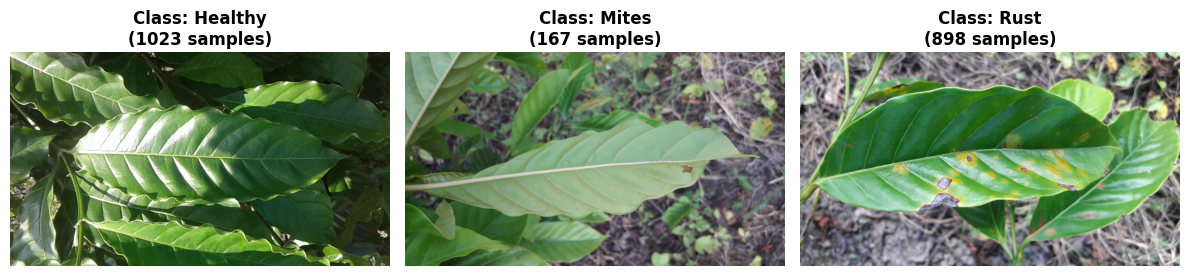

In [19]:
plt.figure(figsize=(12, 4))
for i, cls_name in enumerate(Config.CLASSES):
    cls_files = df_unified[df_unified["label"] == cls_name]["file_path"].tolist()
    if not cls_files:
        continue
    sample_path = random.choice(cls_files)
    img = Image.open(sample_path)
    
    plt.subplot(1, Config.NUM_CLASSES, i + 1)
    plt.imshow(img)
    plt.title(f"Class: {cls_name.capitalize()}\n({len(cls_files)} samples)", fontsize=12, fontweight="bold")
    plt.axis("off")
    
plt.tight_layout()
plt.show()


## ✂️ Step 6: Stratified Train / Validation / Test Split

To strictly avoid **data leakage**, we perform stratified splitting on the raw file paths **before** constructing `tf.data` input pipelines:
- **Train (70%)**: Used to fit model weights
- **Validation (15%)**: Used for hyperparameter tuning, checkpointing, and early stopping
- **Test (15%)**: Held out strictly for final unbiased evaluation

In [20]:
# Create numeric label mapping
class_to_idx = {name: idx for idx, name in enumerate(Config.CLASSES)}
idx_to_class = {idx: name for idx, name in enumerate(Config.CLASSES)}

filepaths = df_unified["file_path"].values
labels_str = df_unified["label"].values
labels_num = np.array([class_to_idx[l] for l in labels_str])

# 1. Split Train (70%) vs Temp (30%)
train_files, temp_files, train_y, temp_y = train_test_split(
    filepaths,
    labels_num,
    test_size=(Config.VAL_SPLIT + Config.TEST_SPLIT),
    stratify=labels_num,
    random_state=Config.SEED
)

# 2. Split Temp (30%) equally into Val (15%) and Test (15%)
val_files, test_files, val_y, test_y = train_test_split(
    temp_files,
    temp_y,
    test_size=0.50,
    stratify=temp_y,
    random_state=Config.SEED
)

print(f"📊 Dataset Split Summary:")
print(f"   • Training:   {len(train_files):>4} samples ({len(train_files)/len(filepaths):.1%})")
print(f"   • Validation: {len(val_files):>4} samples ({len(val_files)/len(filepaths):.1%})")
print(f"   • Test:       {len(test_files):>4} samples ({len(test_files)/len(filepaths):.1%})")
print(f"   • Total:      {len(filepaths):>4} samples")


📊 Dataset Split Summary:
   • Training:   1461 samples (70.0%)
   • Validation:  313 samples (15.0%)
   • Test:        314 samples (15.0%)
   • Total:      2088 samples


## ⚡ Step 7: High-Performance tf.data Pipelines with Augmentation

We construct scalable `tf.data.Dataset` pipelines that:
1. Read and decode images from disk in parallel.
2. Resize images to `224x224` and one-hot encode labels.
3. Apply **data augmentation** (random flip, rotation, zoom, contrast) to the **training set only**.
4. Prefetch batches using `tf.data.AUTOTUNE` to eliminate I/O GPU stalls.

In [21]:
def load_and_preprocess_image(path_tensor, label_tensor):
    """Loads an image from path, decodes as RGB, and resizes to 224x224."""
    img_bytes = tf.io.read_file(path_tensor)
    img = tf.io.decode_image(img_bytes, channels=3, expand_animations=False)
    img = tf.image.resize(img, [Config.IMG_HEIGHT, Config.IMG_WIDTH])
    img = tf.cast(img, tf.float32)
    # One-hot encode label for categorical crossentropy
    label_one_hot = tf.one_hot(label_tensor, depth=Config.NUM_CLASSES)
    return img, label_one_hot

# Keras Data Augmentation layer (applied to training pipeline only)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.12),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.15),
], name="data_augmentation")

AUTOTUNE = tf.data.AUTOTUNE

def build_pipeline(files, labels, is_training=False):
    ds = tf.data.Dataset.from_tensor_slices((files, labels))
    if is_training:
        ds = ds.shuffle(buffer_size=len(files), seed=Config.SEED)
    ds = ds.map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(Config.BATCH_SIZE)
    if is_training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    ds = ds.prefetch(buffer_size=AUTOTUNE)
    return ds

train_ds = build_pipeline(train_files, train_y, is_training=True)
val_ds = build_pipeline(val_files, val_y, is_training=False)
test_ds = build_pipeline(test_files, test_y, is_training=False)

print("✅ tf.data pipelines built successfully.")


✅ tf.data pipelines built successfully.


## 🧠 Step 8: Transfer Learning Model Architecture (MobileNetV2)

We leverage **MobileNetV2** pre-trained on ImageNet:
- Lightweight and ideal for edge devices / local Streamlit deployment.
- Includes native `preprocess_input` (scales pixel range $[0, 255] \rightarrow [-1, 1]$).
- Custom Head: `GlobalAveragePooling2D` ➔ `Dropout(0.3)` ➔ `Dense(128, ReLU)` ➔ `Dense(3, Softmax)`.
- We force `float32` output activation for numerical stability under mixed precision.

In [22]:
def create_coffee_disease_model():
    # 1. Input Layer
    inputs = layers.Input(shape=Config.INPUT_SHAPE, name="leaf_image_input")
    
    # 2. Preprocessing Layer (MobileNetV2 expects [-1, 1])
    x = preprocess_input(inputs)
    
    # 3. Backbone: MobileNetV2 (Feature Extractor frozen in Stage 1)
    base_model = MobileNetV2(
        input_shape=Config.INPUT_SHAPE,
        include_top=False,
        weights="imagenet"
    )
    base_model.trainable = False
    x = base_model(x, training=False)
    
    # 4. Custom Enhanced Classification Head
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.BatchNormalization(name="head_bn1")(x)
    x = layers.Dense(256, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(1e-4), name="dense_256")(x)
    x = layers.BatchNormalization(name="head_bn2")(x)
    x = layers.Dropout(0.35, name="head_dropout1")(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(1e-4), name="dense_128")(x)
    x = layers.Dropout(0.25, name="head_dropout2")(x)
    
    # 5. Output Layer (forced to float32 for mixed precision stability)
    outputs = layers.Dense(
        Config.NUM_CLASSES,
        activation="softmax",
        dtype="float32",
        name="predictions"
    )(x)
    
    model = models.Model(inputs=inputs, outputs=outputs, name="CoffeeLeafDiseaseDetector")
    return model, base_model

model, base_model = create_coffee_disease_model()
model.summary()


Model: "CoffeeLeafDiseaseDetector"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ leaf_image_input (InputLayer)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_bn1 (BatchNormalization)   │ (None, 1280)           │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_bn2 (BatchNormalization)   │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout1 (Dropout)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout2 (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,625,347 (10.01 MB)

 Trainable params: 364,291 (1.39 MB)

 Non-trainable params: 2,261,056 (8.63 MB)

## ⚖️ Step 9: Computing Class Weights

To ensure the model does not become biased toward the most frequent class, we calculate balanced class weights using scikit-learn's `compute_class_weight`.

In [23]:
unique_classes = np.unique(train_y)
raw_weights = class_weight.compute_class_weight(
    class_weight="balanced",
    classes=unique_classes,
    y=train_y
)
# Square-root smoothing dampens extreme spikes while preserving class fairness
smoothed_weights = np.sqrt(raw_weights)
smoothed_weights = smoothed_weights / np.mean(smoothed_weights)
class_weights_dict = {cls_idx: float(w) for cls_idx, w in zip(unique_classes, smoothed_weights)}

print("⚖️ Computed Smoothed Class Weights:")
for idx, w in class_weights_dict.items():
    print(f"   • {idx_to_class[idx]:<10} (class {idx}): {w:.4f}")


⚖️ Computed Smoothed Class Weights:
   • healthy    (class 0): 0.6606
   • mites      (class 1): 1.6341
   • rust       (class 2): 0.7053


## 🛡️ Step 10: Callbacks (Checkpointing, Early Stopping, LR Scheduling)

We set up three safety callbacks:
- **ModelCheckpoint**: Saves the best model checkpoint (`coffee_disease_model.keras`) based on minimum `val_loss`.
- **EarlyStopping**: Restores the best weights if `val_loss` fails to improve for 5 consecutive epochs.
- **ReduceLROnPlateau**: Dynamically drops the learning rate when training plateaus.

In [24]:
best_model_path = os.path.join(Config.OUTPUT_DIR, Config.MODEL_FILENAME)

callback_list = [
    callbacks.ModelCheckpoint(
        filepath=best_model_path,
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]
print(f"✅ Callbacks configured. Best model checkpoint will be saved to: {best_model_path}")


✅ Callbacks configured. Best model checkpoint will be saved to: /kaggle/working/coffee_disease_model.keras


## 🏋️ Step 11: Two-Stage Model Training

1. **Stage 1 (Feature Extraction)**: The MobileNetV2 backbone is frozen. Only the classification head learns at a standard learning rate ($10^{-3}$).
2. **Stage 2 (Fine-Tuning)**: If `FINE_TUNE = True`, the top 30 layers of the backbone are unfrozen and trained together with the head at a very gentle learning rate ($10^{-5}$) to specialize features for coffee leaf textures.

In [25]:
# Compile Stage 1 with Label Smoothing for lower loss & higher generalization
loss_criterion = tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1)

model.compile(
    optimizer=optimizers.Adam(learning_rate=Config.STAGE_1_LR),
    loss=loss_criterion,
    metrics=["accuracy"]
)

print("🚀 Starting Stage 1 Training (Frozen Backbone)...")
history_stage1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=Config.STAGE_1_EPOCHS,
    class_weight=class_weights_dict,
    callbacks=callback_list,
    verbose=1
)

history_stage2 = None
if Config.FINE_TUNE:
    print("\n🔓 Unfreezing top backbone layers for Stage 2 Fine-Tuning...")
    base_model.trainable = True
    # Freeze all layers except the top N layers
    for layer in base_model.layers[:-Config.FINE_TUNE_LAYERS]:
        layer.trainable = False
        
    # Recompile with fine-tuning learning rate and label smoothing
    model.compile(
        optimizer=optimizers.Adam(learning_rate=Config.STAGE_2_LR),
        loss=loss_criterion,
        metrics=["accuracy"]
    )
    
    stage1_epochs_run = len(history_stage1.history["loss"])
    total_epochs = stage1_epochs_run + Config.STAGE_2_EPOCHS
    
    print(f"🚀 Starting Stage 2 Fine-Tuning (Epochs {stage1_epochs_run + 1} to {total_epochs})...")
    history_stage2 = model.fit(
        train_ds,
        validation_data=val_ds,
        initial_epoch=stage1_epochs_run,
        epochs=total_epochs,
        class_weight=class_weights_dict,
        callbacks=callback_list,
        verbose=1
    )


🚀 Starting Stage 1 Training (Frozen Backbone)...
Epoch 1/12
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 385ms/step - accuracy: 0.5166 - loss: 1.0693
Epoch 1: val_loss improved from None to 0.80375, saving model to /kaggle/working/coffee_disease_model.keras

Epoch 1: finished saving model to /kaggle/working/coffee_disease_model.keras
46/46 ━━━━━━━━━━━━━━━━━━━━ 43s 618ms/step - accuracy: 0.6092 - loss: 0.9480 - val_accuracy: 0.7764 - val_loss: 0.8037 - learning_rate: 0.0010
Epoch 2/12
45/46 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 0.7089 - loss: 0.7602
Epoch 2: val_loss did not improve from 0.80375
46/46 ━━━━━━━━━━━━━━━━━━━━ 12s 259ms/step - accuracy: 0.7050 - loss: 0.7487 - val_accuracy: 0.7380 - val_loss: 0.8235 - learning_rate: 0.0010
Epoch 3/12
45/46 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.7211 - loss: 0.7214
Epoch 3: val_loss improved from 0.80375 to 0.76761, saving model to /kaggle/working/coffee_disease_model.keras

Epoch 3: finished saving model to /kaggle/working/coffee_disease

## 🧪 Step 12: Unbiased Test Set Evaluation & Curves

We evaluate the saved best model checkpoint on the **unseen Test set**.
We print the Scikit-Learn **Classification Report** and save:
1. `training_curves.png`: Training vs. Validation Loss and Accuracy.
2. `confusion_matrix.png`: Normalized Seaborn confusion matrix heatmap.

📂 Loading best checkpoint from /kaggle/working/coffee_disease_model.keras...

🎯 Unseen Test Set Accuracy: 0.7643 (76.43%)

📄 Classification Report:
              precision    recall  f1-score   support

     healthy     0.8667    0.8442    0.8553       154
       mites     0.3030    0.4000    0.3448        25
        rust     0.7634    0.7407    0.7519       135

    accuracy                         0.7643       314
   macro avg     0.6444    0.6616    0.6507       314
weighted avg     0.7774    0.7643    0.7702       314



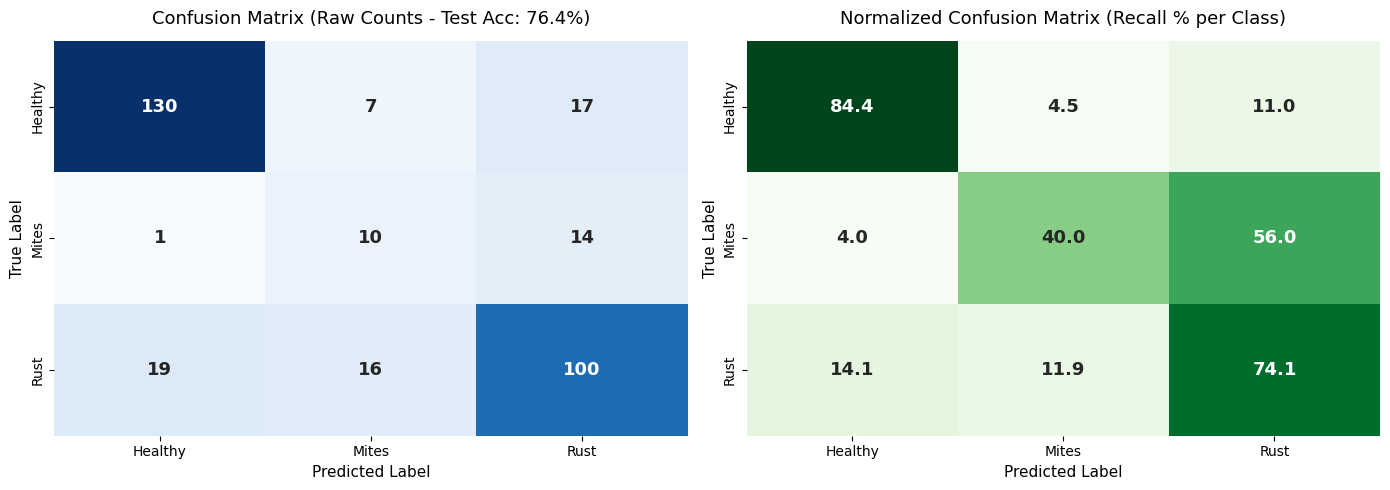

💾 Confusion matrix saved to: /kaggle/working/confusion_matrix.png


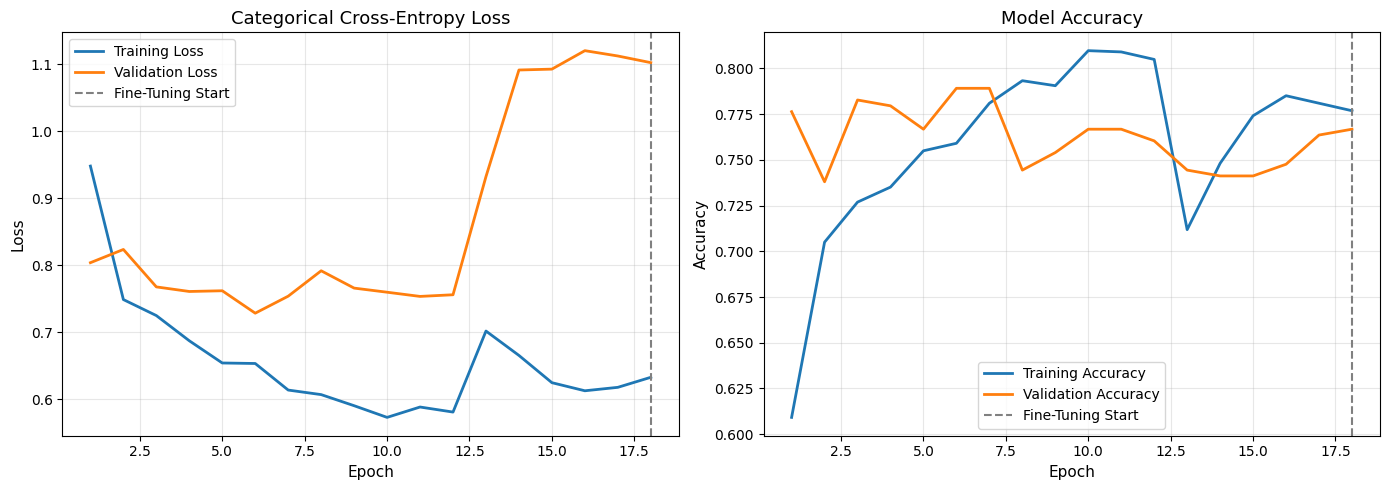

💾 Training curves saved to: /kaggle/working/training_curves.png


In [26]:
# Load the verified best model saved by ModelCheckpoint
print(f"📂 Loading best checkpoint from {best_model_path}...")
eval_model = models.load_model(best_model_path)

# Gather test predictions
y_pred_probs = []
y_true = []

for batch_x, batch_y in test_ds:
    probs = eval_model.predict(batch_x, verbose=0)
    y_pred_probs.append(probs)
    y_true.append(np.argmax(batch_y.numpy(), axis=1))

y_pred_probs = np.vstack(y_pred_probs)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.concatenate(y_true)

test_acc = accuracy_score(y_true, y_pred)
print(f"\n🎯 Unseen Test Set Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)\n")

print("📄 Classification Report:")
print(classification_report(y_true, y_pred, target_names=Config.CLASSES, digits=4))

# 1. Plot & Save Dual Confusion Matrix (Raw Counts + Normalized Recall %)
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype("float") / np.maximum(cm.sum(axis=1)[:, np.newaxis], 1e-9) * 100
display_classes = [c.capitalize() for c in Config.CLASSES]

plt.figure(figsize=(14, 5))
# Subplot 1: Raw Counts
plt.subplot(1, 2, 1)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=display_classes,
    yticklabels=display_classes,
    cbar=False,
    annot_kws={"size": 13, "weight": "bold"}
)
plt.title(f"Confusion Matrix (Raw Counts - Test Acc: {test_acc*100:.1f}%)", fontsize=13, pad=12)
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("True Label", fontsize=11)

# Subplot 2: Normalized Percentages (Recall % per Class)
plt.subplot(1, 2, 2)
sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".1f",
    cmap="Greens",
    xticklabels=display_classes,
    yticklabels=display_classes,
    cbar=False,
    annot_kws={"size": 13, "weight": "bold"}
)
plt.title("Normalized Confusion Matrix (Recall % per Class)", fontsize=13, pad=12)
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("True Label", fontsize=11)
plt.tight_layout()
cm_save_path = os.path.join(Config.OUTPUT_DIR, Config.CONF_MATRIX_FILENAME)
plt.savefig(cm_save_path, dpi=300)
plt.show()
print(f"💾 Confusion matrix saved to: {cm_save_path}")

# 2. Combine and Plot Training History Curves
train_loss = history_stage1.history["loss"]
val_loss = history_stage1.history["val_loss"]
train_acc = history_stage1.history["accuracy"]
val_acc = history_stage1.history["val_accuracy"]

if history_stage2 is not None:
    train_loss += history_stage2.history["loss"]
    val_loss += history_stage2.history["val_loss"]
    train_acc += history_stage2.history["accuracy"]
    val_acc += history_stage2.history["val_accuracy"]

epochs_range = range(1, len(train_loss) + 1)

plt.figure(figsize=(14, 5))
# Loss Subplot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_loss, label="Training Loss", color="#1f77b4", lw=2)
plt.plot(epochs_range, val_loss, label="Validation Loss", color="#ff7f0e", lw=2)
if history_stage2 is not None:
    plt.axvline(x=len(history_stage1.history["loss"]), color="gray", linestyle="--", label="Fine-Tuning Start")
plt.title("Categorical Cross-Entropy Loss", fontsize=13)
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Loss", fontsize=11)
plt.legend()
plt.grid(True, alpha=0.3)

# Accuracy Subplot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_acc, label="Training Accuracy", color="#1f77b4", lw=2)
plt.plot(epochs_range, val_acc, label="Validation Accuracy", color="#ff7f0e", lw=2)
if history_stage2 is not None:
    plt.axvline(x=len(history_stage1.history["loss"]), color="gray", linestyle="--", label="Fine-Tuning Start")
plt.title("Model Accuracy", fontsize=13)
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Accuracy", fontsize=11)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
curves_save_path = os.path.join(Config.OUTPUT_DIR, Config.CURVES_PLOT_FILENAME)
plt.savefig(curves_save_path, dpi=300)
plt.show()
print(f"💾 Training curves saved to: {curves_save_path}")


## 💾 Step 13: Export Class Indices Mapping

We save `class_indices.json` to guarantee the Streamlit web application decodes predictions in the exact same order as training.

In [27]:
class_indices_path = os.path.join(Config.OUTPUT_DIR, Config.CLASS_INDICES_FILENAME)
with open(class_indices_path, "w") as f:
    json.dump(class_to_idx, f, indent=2)

print(f"✅ Class indices exported to: {class_indices_path}")
with open(class_indices_path, "r") as f:
    print(f.read())


✅ Class indices exported to: /kaggle/working/class_indices.json
{
  "healthy": 0,
  "mites": 1,
  "rust": 2
}


## 🚀 Step 14: Deployment Checklist & Download Instructions

Congratulations! Your model is trained, evaluated, and ready for deployment.

### 📥 Files to Download from Kaggle Working Directory (`/kaggle/working`):
1. **`coffee_disease_model.keras`** — Trained MobileNetV2 model weights & architecture.
2. **`class_indices.json`** — Class mapping dictionary.
3. **`training_curves.png`** — Loss & accuracy curves.
4. **`confusion_matrix.png`** — Confusion matrix visualization.

### 💻 Local Streamlit Setup:
Place `coffee_disease_model.keras` and `class_indices.json` in the same directory as `app.py`:
```bash
coffee/
├── app.py
├── class_indices.json          <- Downloaded from Kaggle
├── coffee_disease_model.keras  <- Downloaded from Kaggle
└── ...
```
Then launch your interactive web application:
```bash
streamlit run app.py
```

In [28]:
print("==================================================================")
print("🎉 ALL TRAINING & EXPORT STEPS COMPLETED SUCCESSFULLY!")
print("==================================================================")
print("Artifacts generated in output directory:")
for fname in [Config.MODEL_FILENAME, Config.CLASS_INDICES_FILENAME, Config.CURVES_PLOT_FILENAME, Config.CONF_MATRIX_FILENAME]:
    fpath = os.path.join(Config.OUTPUT_DIR, fname)
    if os.path.exists(fpath):
        size_mb = os.path.getsize(fpath) / (1024 * 1024)
        print(f"   • {fname:<28} ({size_mb:.2f} MB)")
print("==================================================================")


🎉 ALL TRAINING & EXPORT STEPS COMPLETED SUCCESSFULLY!
Artifacts generated in output directory:
   • coffee_disease_model.keras   (16.17 MB)
   • class_indices.json           (0.00 MB)
   • training_curves.png          (0.31 MB)
   • confusion_matrix.png         (0.14 MB)
